# Test 2 – Does our simulation predict where SPY actually goes?

In **Test 1** (`Market_Comparison.ipynb`) we compared our option prices with what traders pay.
That told us whether we *agree with the market*, but not whether the model describes *reality*.

This notebook asks the more basic question:

> **When our simulation says "SPY will probably end up between \$X and \$Y a month from now", is that true?**

### The idea: a weather-forecast check
A weather forecaster says *"90% chance tomorrow is between 10° and 20°"*. To judge them, you don't look at one day –
you look at 100 days and count. If the temperature landed inside their range about **90** times, they're good.
If only 70 times, they're **overconfident** (ranges too narrow). If 100 times, they're **too cautious** (ranges too wide).

We do exactly that with SPY:

1. **Go back in time** to a past date, say 10 Feb 2025. Pretend we don't know anything after that day.
2. **Estimate volatility $\sigma$** using only the 60 days *before* that date (no peeking at the future!).
3. **Simulate** 10,000 possible SPY prices **one month (21 trading days) later**.
4. **Look up** where SPY *actually* was a month later, and note where it fell inside our 10,000 simulations.
5. **Move forward one week** and repeat – about 85 forecasts over 2 years.
6. **Count**: did reality land inside our ranges as often as the model promised?

### Why this test matters
* It judges the **simulation itself** – no traders' opinions involved.
* It's exactly what **Value at Risk (VaR)** relies on: VaR is just "the 5th-percentile loss". If the 5th percentile is
  wrong, the VaR is wrong.

In [19]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

project_root = Path.cwd().resolve()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import percentile_bands, simulate_gbm_paths
from src.backtest import coverage_summary, rolling_forecast_check
from src.market_data import load_price_history, load_risk_free_rate, realized_volatility

pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams["figure.dpi"] = 110

## 1. Load the data

Two years of SPY daily prices and the risk-free rate, saved earlier in `data/raw/`.

We use **adjusted** prices (`adj_close`): when SPY pays a dividend its price drops by that amount, but you
didn't actually lose money – you got the cash. Adjusted prices smooth that out so dividends don't look like crashes.

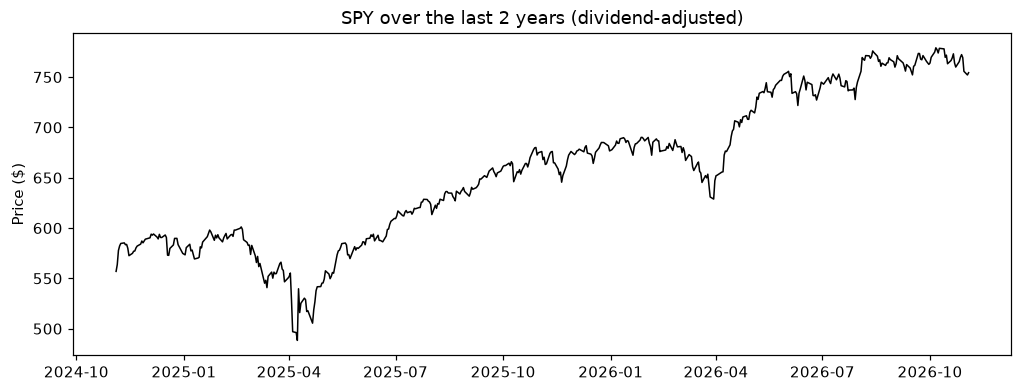

2024-11-04 -> 2026-11-03, 501 trading days


In [20]:
prices = load_price_history("SPY")
rates = load_risk_free_rate()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(prices.date, prices.adj_close, color="black", lw=1)
ax.set(title="SPY over the last 2 years (dividend-adjusted)", ylabel="Price ($)")
plt.show()
print(f"{prices.date.min().date()} -> {prices.date.max().date()}, {len(prices)} trading days")

## 2. One forecast, step by step

Before running 85 forecasts, let's look at a single one so the idea is concrete.

We stand on a past date, estimate $\sigma$ from the previous 60 days, and simulate 1,000 paths one month ahead.
Then we draw what **actually** happened on top.

The "fan" is our forecast. The orange bands are the middle 50% and 90% of simulated outcomes.

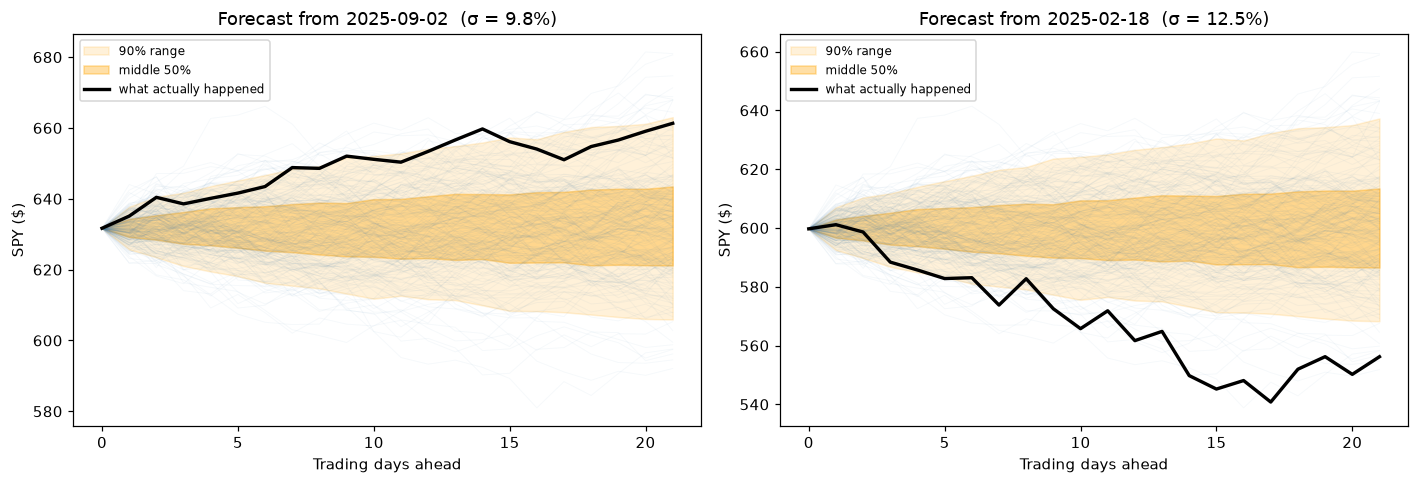

In [21]:
HORIZON = 21          # trading days ahead (~ 1 month)
VOL_WINDOW = 60       # days of history used to estimate sigma

px = prices.set_index("date").adj_close
vol = realized_volatility(px, window=VOL_WINDOW)
r_by_date = rates.set_index("date").r_cont

def show_one_forecast(start, ax):
    i = px.index.get_indexer([pd.Timestamp(start)], method="bfill")[0]
    s0, sigma, r = px.iloc[i], vol.iloc[i], r_by_date.asof(px.index[i])
    T = HORIZON / 252
    paths = simulate_gbm_paths(s0, r, sigma, T, HORIZON, 1_000, rng=np.random.default_rng(1))
    bands = percentile_bands(paths, (5, 25, 75, 95))
    days = np.arange(HORIZON + 1)
    real = px.iloc[i : i + HORIZON + 1].values

    ax.plot(days, paths[:200].T, color="steelblue", alpha=0.05, lw=0.6)
    ax.fill_between(days, bands[5], bands[95], color="orange", alpha=0.15, label="90% range")
    ax.fill_between(days, bands[25], bands[75], color="orange", alpha=0.35, label="middle 50%")
    ax.plot(days, real, color="black", lw=2.2, label="what actually happened")
    ax.set(title=f"Forecast from {px.index[i].date()}  (σ = {sigma:.1%})", xlabel="Trading days ahead", ylabel="SPY ($)")
    ax.legend(loc="upper left", fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
show_one_forecast("2025-09-02", axes[0])   # a calm month
show_one_forecast("2025-02-18", axes[1])   # just before a sharp sell-off
plt.tight_layout(); plt.show()

* **Left:** a strong month – SPY climbed steadily and finished right at the top edge of the 90% range, but still (just) inside.
* **Right:** the forecast was made during a calm spell, so $\sigma$ was small and the fan was narrow.
  Then the market dropped sharply and the real price fell **out of the bottom** of the fan.

One forecast can't tell us whether the model is good or bad – the left could be luck and the right could be bad luck.
That's why we repeat it many times.

## 3. Run ~85 forecasts

`rolling_forecast_check` (in `src/backtest.py`) does steps 1–5 from the intro for every week in the data.
For each forecast it stores:

| column | meaning |
|---|---|
| `start_date` / `end_date` | forecast made on start_date, checked a month later on end_date |
| `s0`, `actual` | SPY's price on those two days |
| `sigma` | the volatility estimate used (from the 60 days before start_date) |
| `p5 … p95` | the 5th, 25th, 50th, 75th, 95th percentile of the 10,000 simulated end prices |
| `rank` | **what fraction of simulations ended *below* the real price** (0 to 1) |

`rank` is the key number. `rank = 0.03` means reality was lower than 97% of our simulations – a big miss to the downside.
`rank = 0.50` means reality landed right in the middle.

In [22]:
check = rolling_forecast_check(prices, rates, horizon=HORIZON, step=5, vol_window=VOL_WINDOW, n_sims=10_000, seed=0)
print(f"{len(check)} forecasts, made between {check.start_date.min().date()} and {check.start_date.max().date()}")
check.head()

84 forecasts, made between 2025-02-03 and 2026-09-29


,start_date,end_date,s0,actual,sigma,r,rank,z,p5,p25,p50,p75,p95
0,2025-02-03,2025-03-05,586.253,571.826,0.137,0.041,0.240,-0.698,551.215,572.549,587.588,604.056,627.112
1,2025-02-10,2025-03-12,593.196,548.102,0.127,0.041,0.013,-2.226,560.685,580.448,594.747,610.009,631.459
2,2025-02-18,2025-03-19,599.708,556.203,0.125,0.041,0.017,-2.162,567.217,587.121,601.503,616.135,638.058
3,2025-02-25,2025-03-26,582.791,559.312,0.131,0.041,0.129,-1.162,548.656,569.496,584.316,599.337,622.103
4,2025-03-04,2025-04-02,565.746,555.309,0.144,0.041,0.308,-0.510,529.400,551.166,567.102,583.473,606.494


## 4. Forecast vs reality – the big picture

Each vertical bar is one forecast, drawn at the date it was checked:
* thin bar = the **90% range** (5th–95th percentile), thick bar = the **middle 50%**,
* dot = where SPY **actually** was. **Green** = inside the 90% range, **red** = outside.

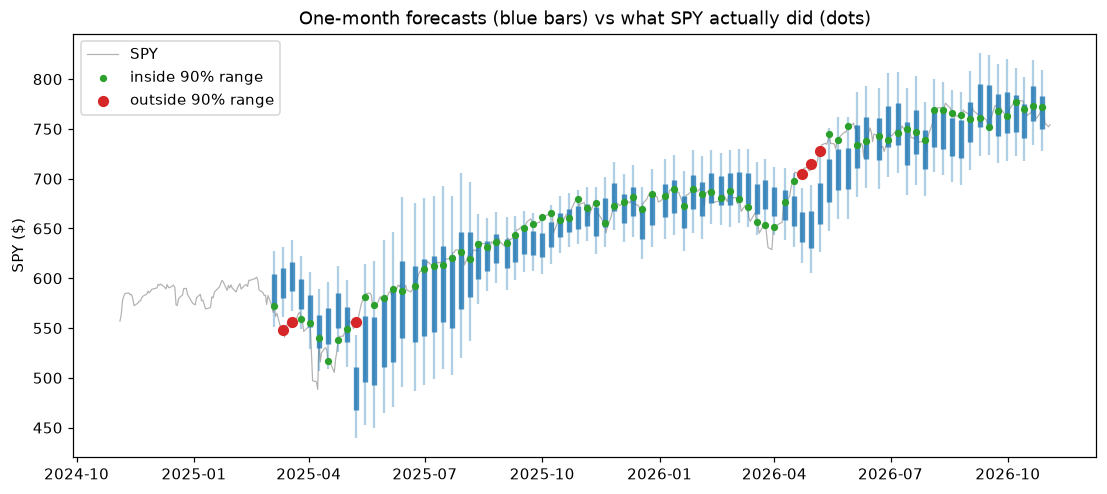

In [23]:
inside = (check["rank"] >= 0.05) & (check["rank"] <= 0.95)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(prices.date, prices.adj_close, color="grey", lw=0.8, alpha=0.6, label="SPY")
ax.vlines(check.end_date, check.p5, check.p95, color="tab:blue", alpha=0.35, lw=1.5)
ax.vlines(check.end_date, check.p25, check.p75, color="tab:blue", alpha=0.8, lw=3.5)
ax.scatter(check.end_date[inside], check.actual[inside], s=14, color="tab:green", zorder=3, label="inside 90% range")
ax.scatter(check.end_date[~inside], check.actual[~inside], s=40, color="tab:red", zorder=4, label="outside 90% range")
ax.set(title="One-month forecasts (blue bars) vs what SPY actually did (dots)", ylabel="SPY ($)")
ax.legend(loc="upper left"); plt.show()

Notice the bars aren't all the same size: after a volatile period $\sigma$ goes up and the bars get longer;
after a calm period they shrink. Also notice **when** the red dots happen – they tend to come in clusters, not randomly.

## 5. The scorecard

Now we count. If the model is right, reality should land:

| range | how often (if the model is right) |
|---|---|
| below the 5th percentile | 5% of the time |
| 5th – 25th | 20% |
| 25th – 75th (the middle half) | 50% |
| 75th – 95th | 20% |
| above the 95th percentile | 5% |
| **inside the 90% range** | **90%** |

### What's the `p_value`?
Even a perfect model won't hit *exactly* 90% – with ~85 tries, luck alone can easily give 86% or 94%.
The p-value answers: **"if the model were perfect, how likely is a gap at least this big, just by luck?"**

* p-value **above 0.05** → the gap could easily be luck. No evidence the model is wrong.
* p-value **below 0.05** → a gap this big would be unusual by luck alone. The model is probably off in this range.

In [24]:
score = coverage_summary(check)
show = score.copy()
show["expected"] = show.expected.map("{:.0%}".format)
show["actual"] = show.actual.map("{:.0%}".format)
show

,expected,actual,count,p_value
range,,,,
below 5th pct (big miss down),5%,2%,2 / 84,0.446
5th-25th pct,20%,10%,8 / 84,0.014
25th-75th pct (middle half),50%,63%,53 / 84,0.021
75th-95th pct,20%,20%,17 / 84,1.000
above 95th pct (big miss up),5%,5%,4 / 84,1.000
inside 5th-95th (the 90% range),90%,93%,78 / 84,0.469


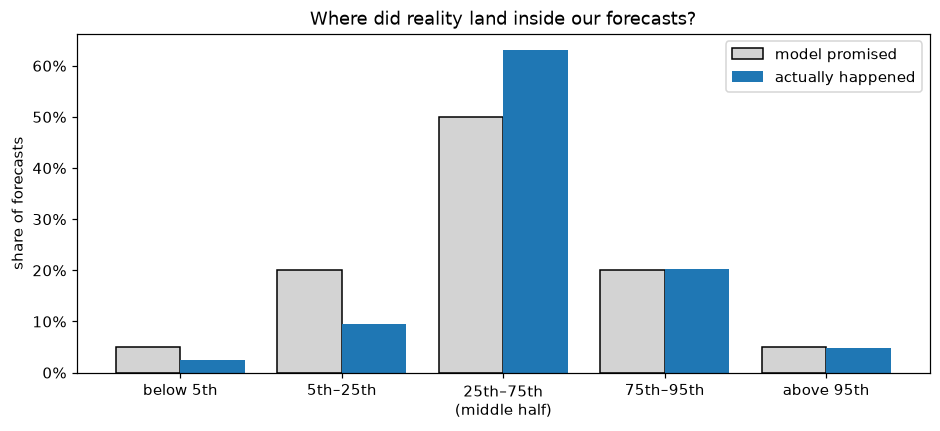

In [25]:
s = score.iloc[:5]
x = np.arange(len(s))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - 0.2, s.expected, width=0.4, label="model promised", color="lightgrey", edgecolor="black")
ax.bar(x + 0.2, s.actual, width=0.4, label="actually happened", color="tab:blue")
ax.set_xticks(x, ["below 5th", "5th–25th", "25th–75th\n(middle half)", "75th–95th", "above 95th"])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set(title="Where did reality land inside our forecasts?", ylabel="share of forecasts")
ax.legend(); plt.show()

## 6. Another view: how big were the surprises?

For each forecast we can measure the real one-month move in units of **"how big the model expected a typical move to be"**.
This is called a **z-score**:

$$z = \frac{\text{actual move} - \text{expected move}}{\text{typical move size } (\sigma\sqrt{T})}$$

(Moves are measured as log-returns, $\ln(S_{\text{end}}/S_0)$, which is roughly the % change.)

If the model is right, the $z$'s should follow the classic **bell curve** with average 0 and spread 1:
* about 68% between –1 and +1,
* about 95% between –2 and +2,
* almost never beyond ±3.

What to look for:
* **Spread (sd) bigger than 1** → reality is jumpier than the model thinks → ranges too narrow → risky!
* **Spread smaller than 1** → reality was calmer than the model thought → ranges too wide (too cautious).
* **Average above 0** → SPY rose faster than the model assumed.

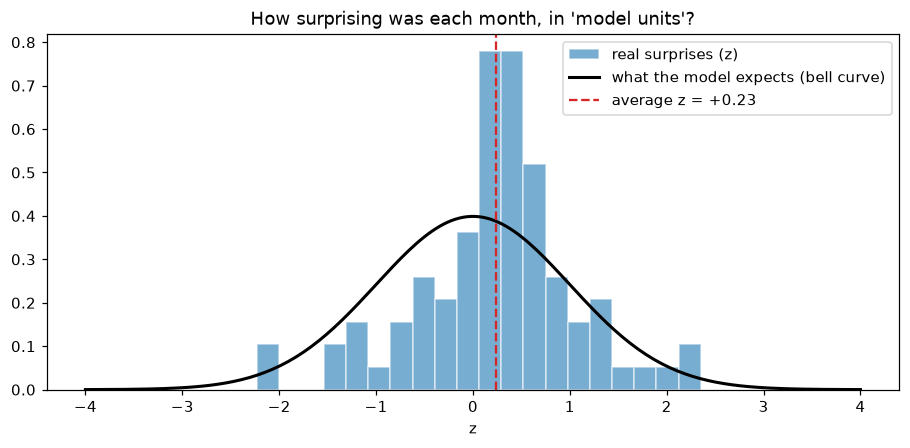

average z          : +0.23   (model says 0)
spread (sd) of z   : 0.84    (model says 1)
share with |z| > 2 : 4.8%  (model says ~4.6%)


In [26]:
z = check.z
grid = np.linspace(-4, 4, 200)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(z, bins=20, density=True, color="tab:blue", alpha=0.6, edgecolor="white", label="real surprises (z)")
ax.plot(grid, stats.norm.pdf(grid), color="black", lw=2, label="what the model expects (bell curve)")
ax.axvline(z.mean(), color="tab:red", ls="--", label=f"average z = {z.mean():+.2f}")
ax.set(title="How surprising was each month, in 'model units'?", xlabel="z")
ax.legend(); plt.show()

print(f"average z          : {z.mean():+.2f}   (model says 0)")
print(f"spread (sd) of z   : {z.std():.2f}    (model says 1)")
print(f"share with |z| > 2 : {(z.abs() > 2).mean():.1%}  (model says ~4.6%)")

## 7. Does it matter how we estimate $\sigma$?

We used the last 60 days. Let's try:
* **30 days** – reacts faster to changes, but noisier,
* **60 days** – our default,
* **all history so far** – very stable, but slow to react.

In [27]:
rows = {}
for label, window in [("30-day σ", 30), ("60-day σ", 60), ("all-history σ", 0)]:
    c = rolling_forecast_check(prices, rates, horizon=HORIZON, step=5, vol_window=window, seed=0)
    sc = coverage_summary(c)
    rows[label] = {
        "forecasts": len(c),
        "inside 90% range": sc.loc["inside 5th-95th (the 90% range)", "actual"],
        "below 5th (big miss down)": sc.loc["below 5th pct (big miss down)", "actual"],
        "above 95th (big miss up)": sc.loc["above 95th pct (big miss up)", "actual"],
        "sd of z (want 1)": c.z.std(),
        "avg z (want 0)": c.z.mean(),
    }
compare_windows = pd.DataFrame(rows).T
compare_windows.style.format({
    "forecasts": "{:.0f}", "inside 90% range": "{:.0%}", "below 5th (big miss down)": "{:.0%}",
    "above 95th (big miss up)": "{:.0%}", "sd of z (want 1)": "{:.2f}", "avg z (want 0)": "{:+.2f}",
})

,forecasts,inside 90% range,below 5th (big miss down),above 95th (big miss up),sd of z (want 1),avg z (want 0)
30-day σ,90,96%,2%,2%,0.79,+0.25
60-day σ,84,93%,2%,5%,0.84,+0.23
all-history σ,92,96%,2%,2%,0.72,+0.17


## 8. Takeaways

*(Written from data up to 2026-11-03. The numbers above update if you refresh the data.)*

1. **Overall, the model's ranges were about right – if anything a bit too wide.** Reality landed inside the
   90% range roughly 93% of the time (promised: 90%), and the spread of surprises (sd of $z$ ≈ 0.8) was a little *smaller*
   than the model expected. Over these two years, a history-based $\sigma$ did **not** underestimate risk overall.
2. **But the misses aren't random – they cluster.** The two downside misses both come from forecasts made during
   the calm stretch of February 2025, right before the sharp sell-off. The upside misses come from the fast **rebounds**
   (May 2025, and April–May 2026). The model only "learns" that the market is jumpy *after* the jump. This is called
   **volatility clustering**: calm periods and wild periods come in streaks, and a fixed-$\sigma$ model is always one step behind.
3. **The test only looks at the end of each month – and can miss a crash in between.** Look at April 2025 on the
   big chart: SPY briefly fell to about \$490, but that low landed *between* two check dates, so it never shows up as
   a miss. Someone holding SPY would certainly have felt it. A tougher version of this test would also check the
   **lowest** price during each month, not just the final one.
4. **Too many results in the middle, too few in the "slightly low" range.** The middle-half bucket (25th–75th)
   was hit noticeably more than 50%, and the 5th–25th bucket noticeably less than 20% – the only gaps with small p-values.
   Partly that's because SPY mostly **went up** over these two years (average $z$ > 0): the model assumes the price grows
   only at the risk-free rate $r$, but stocks usually grow faster than that on average.
5. **Link to Test 1.** In Test 1 the market priced options with ~17% volatility, while history said ~10% – and here
   history-based ranges were already *wide enough* on average. That fits a well-known pattern called the
   **volatility risk premium**: option buyers usually pay for more volatility than actually shows up, because they want
   protection against exactly those sudden, clustered crashes (points 2 and 3).

### Be careful with these conclusions
* **Only ~85 forecasts over 2 years**, and they overlap (a forecast made each week covers a month, so neighbouring
  forecasts share 3 weeks of data). Real evidence is weaker than the count suggests, and the p-values are a bit
  too optimistic.
* **Two years is one "market mood".** A period with a long crash (like 2008 or 2020) would likely show many more
  downside misses. Downloading 10+ years (`fetch_price_history(period="10y")`) would make this test much stronger.

### What this means for VaR
VaR = "the loss we only exceed 5% of the time" = the 5th percentile of these forecasts. Here the 5th percentile was
breached about as rarely as promised – but **all at once** in a single sell-off. A good risk report should show
VaR **and** how badly things go when it's breached (Expected Shortfall), and should be re-checked like this regularly.